# Dataset overview

Inspect file sizes, recording lengths, and signals to understand the dataset.

Source: [UCI](https://archive.ics.uci.edu/dataset/340/cuff%2Bless%2Bblood%2Bpressure%2Bestimation). Run from `notebooks/` with all four files in the repo's `data/` folder.


In [2]:
from pathlib import Path
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

FS = 125
WINDOW = 5 * FS
files = [Path('../data') / f'Part_{i}.mat' for i in range(1, 5)]

for path in files:
    if not path.is_file():
        raise FileNotFoundError(path)

## File sizes and recording lengths

Read HDF5 references and shapes to count recordings and measure their lengths without loading all signals. Counts are recordings, not verified patients.


In [3]:
file_rows = []
length_rows = []

for path in files:
    with h5py.File(path, 'r') as f:
        refs = f[path.stem]
        file_rows.append({
            'file': path.name,
            'size_GB': path.stat().st_size / 1e9,
            'recordings': len(refs),
        })
        for index, ref in enumerate(refs[:, 0]):
            shape = f[ref].shape
            if len(shape) != 2 or 3 not in shape:
                raise ValueError(f'{path.name}, record {index}: unexpected shape {shape}')
            samples = shape[0] if shape[1] == 3 else shape[1]
            length_rows.append({
                'file': path.name,
                'record_index': index,
                'samples': samples,
                'seconds': samples / FS,
                'windows': samples // WINDOW,
            })

inventory = pd.DataFrame(file_rows)
lengths = pd.DataFrame(length_rows)
print(inventory.round(3).to_string(index=False))
print(f"Total size: {inventory['size_GB'].sum():.3f} GB")
print(f"Total recordings: {inventory['recordings'].sum():,}")

      file  size_GB  recordings
Part_1.mat    0.851        3000
Part_2.mat    0.973        3000
Part_3.mat    0.719        3000
Part_4.mat    0.867        3000
Total size: 3.411 GB
Total recordings: 12,000


Recording duration in seconds:
            min  median    max
file                          
Part_1.mat  8.0   152.0  592.0
Part_2.mat  8.0   216.0  592.0
Part_3.mat  8.0   104.0  592.0
Part_4.mat  8.0   168.0  592.0
Complete five-second windows before quality filtering: 528,828


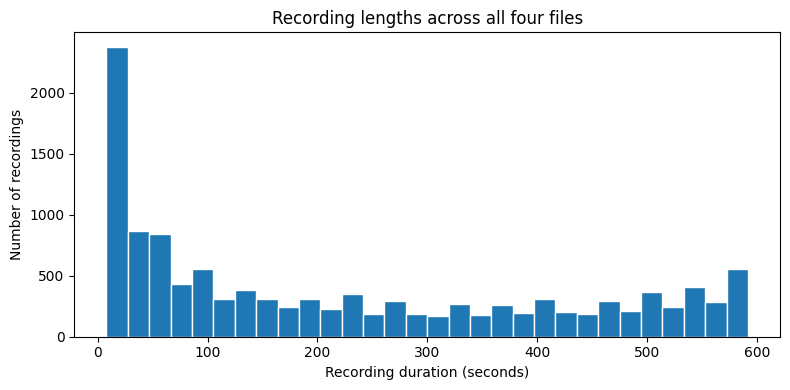

In [4]:
summary = lengths.groupby('file')['seconds'].agg(['min', 'median', 'max'])
print('Recording duration in seconds:')
print(summary.round(2).to_string())
print(f"Complete five-second windows before quality filtering: {lengths['windows'].sum():,}")

plt.figure(figsize=(8, 4))
plt.hist(lengths['seconds'], bins=30, edgecolor='white')
plt.xlabel('Recording duration (seconds)')
plt.ylabel('Number of recordings')
plt.title('Recording lengths across all four files')
plt.tight_layout()
plt.show()

## Signal examples

Show five seconds of PPG, ABP, and ECG from recording 0 in each file to compare their shapes. Sampling rate: 125 Hz.


In [5]:
def read_record(path, index=0):
    with h5py.File(path, 'r') as f:
        record = f[f[path.stem][index, 0]][:]
    return record if record.shape[1] == 3 else record.T

record = read_record(files[0])
print('Part_1, recording 0 shape:', record.shape)
print(pd.DataFrame(record[:10], columns=['PPG', 'ABP', 'ECG']).to_string(index=False))

Part_1, recording 0 shape: (61000, 3)
     PPG        ABP       ECG
1.759531  67.062955 -0.060606
1.718475  69.358628 -0.075269
1.684262  75.366453 -0.070381
1.657869  85.037586 -0.035191
1.637341  96.222885  0.024438
1.615836 105.942862  0.089932
1.593353 112.927569  0.154936
1.570870 117.665447  0.204790
1.549365 120.986846  0.249756
1.526882 123.184831  0.274682


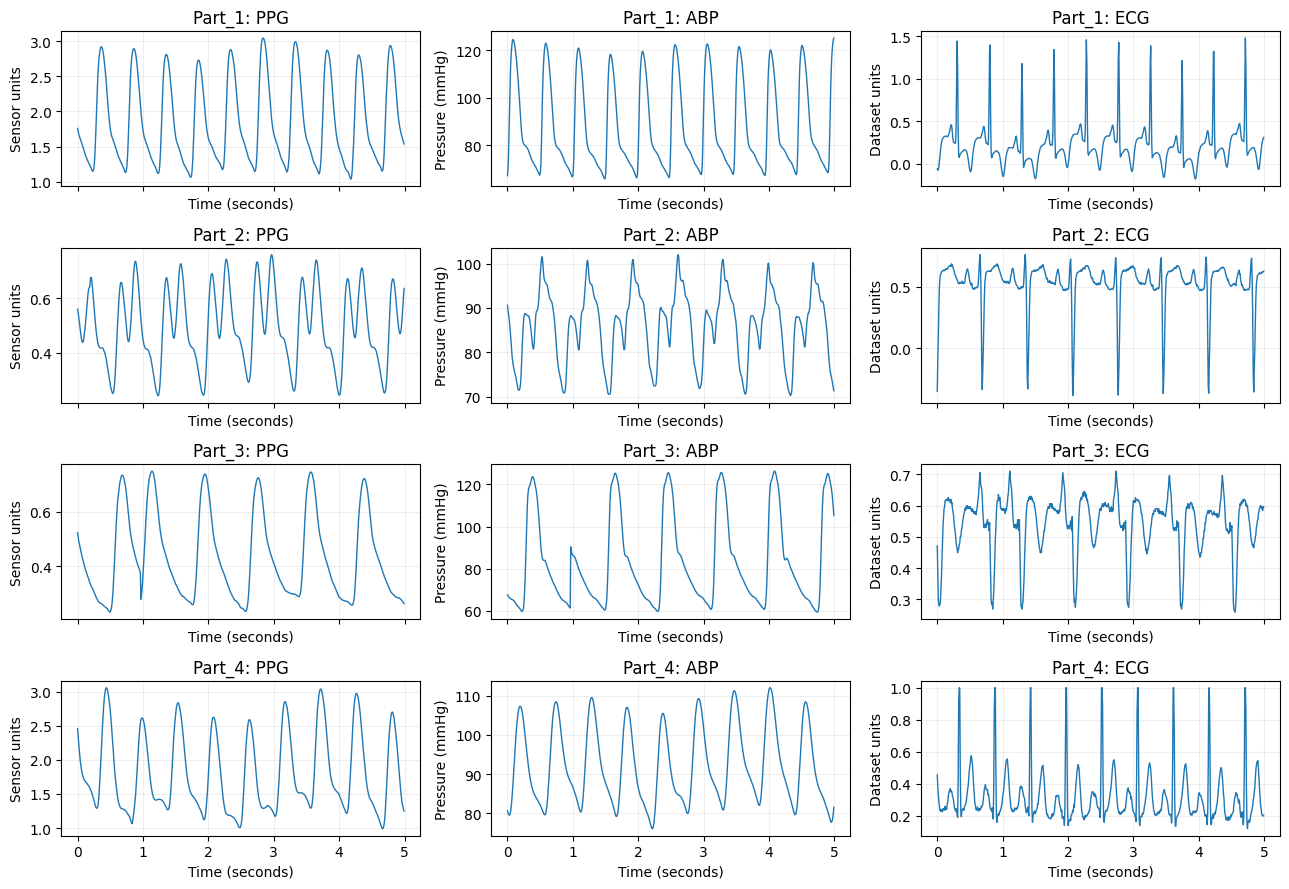

In [6]:
fig, axes = plt.subplots(4, 3, figsize=(13, 9), sharex=True)
channels = ['PPG', 'ABP', 'ECG']
units = ['Sensor units', 'Pressure (mmHg)', 'Dataset units']

for row, path in enumerate(files):
    example = read_record(path)[:WINDOW]
    time_seconds = np.arange(len(example)) / FS
    for column, channel in enumerate(channels):
        ax = axes[row, column]
        ax.plot(time_seconds, example[:, column], linewidth=1)
        ax.set_title(f'{path.stem}: {channel}')
        ax.set_ylabel(units[column])
        ax.set_xlabel('Time (seconds)')
        ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

## Basic signal checks

Check missing values and ranges in Part_1, recording 0 to identify obvious data issues.


In [7]:
values = pd.DataFrame(record, columns=channels)
print(values.agg(['min', 'max', 'std']).round(3).to_string())
print('Missing samples:', values.isna().sum().to_dict())
print('Infinite samples:', dict(zip(channels, np.isinf(record).sum(axis=0).tolist())))
print('Complete five-second windows:', len(record) // WINDOW)
print('Leftover samples:', len(record) % WINDOW)

       PPG      ABP    ECG
min  0.000   50.163 -0.240
max  4.002  160.111  1.501
std  0.632   20.567  0.255
Missing samples: {'PPG': 0, 'ABP': 0, 'ECG': 0}
Infinite samples: {'PPG': 0, 'ABP': 0, 'ECG': 0}
Complete five-second windows: 97
Leftover samples: 375


## SBP and DBP labels

Average ABP peaks for SBP and troughs for DBP using the original notebook settings. This shows how five-second windows receive labels in Part_1, recording 0.


In [8]:
label_rows = []

for start in range(0, len(record) - WINDOW + 1, WINDOW):
    abp = record[start:start + WINDOW, 1]
    peaks, _ = find_peaks(abp, distance=int(0.4 * FS), prominence=5)
    troughs, _ = find_peaks(-abp, distance=int(0.4 * FS), prominence=5)
    if len(peaks) < 2 or len(troughs) < 2:
        continue
    sbp = abp[peaks].mean()
    dbp = abp[troughs].mean()
    if 50 <= sbp <= 230 and 30 <= dbp <= 140 and sbp > dbp:
        label_rows.append({
            'file': files[0].name,
            'record_index': 0,
            'start_sample': start,
            'sbp': sbp,
            'dbp': dbp,
        })

labels = pd.DataFrame(label_rows)
print('Example windows kept:', len(labels))
print(labels.head().round(2).to_string(index=False))

Example windows kept: 97
      file  record_index  start_sample    sbp   dbp
Part_1.mat             0             0 121.55 66.97
Part_1.mat             0           625 124.70 68.82
Part_1.mat             0          1250 125.73 69.50
Part_1.mat             0          1875 122.17 67.30
Part_1.mat             0          2500 125.20 69.33


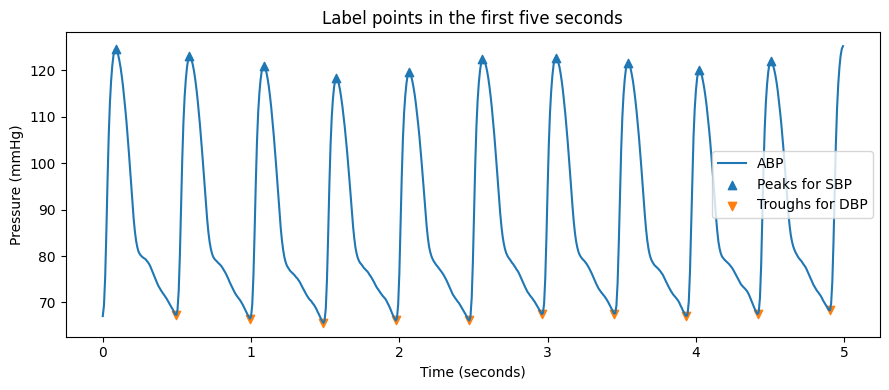

In [9]:
abp = record[:WINDOW, 1]
time_seconds = np.arange(len(abp)) / FS
peaks, _ = find_peaks(abp, distance=int(0.4 * FS), prominence=5)
troughs, _ = find_peaks(-abp, distance=int(0.4 * FS), prominence=5)

plt.figure(figsize=(9, 4))
plt.plot(time_seconds, abp, label='ABP')
plt.scatter(time_seconds[peaks], abp[peaks], marker='^', label='Peaks for SBP')
plt.scatter(time_seconds[troughs], abp[troughs], marker='v', label='Troughs for DBP')
plt.xlabel('Time (seconds)')
plt.ylabel('Pressure (mmHg)')
plt.title('Label points in the first five seconds')
plt.legend()
plt.tight_layout()
plt.show()